# 01 - Baseline (SVM lineal) y modelos candidatos

Replica el protocolo del paper original para el SVM lineal (baseline) y lo compara con tres modelos candidatos sencillos. Antes de ejecutar: `make data`.

## Protocolo

Como en el paper, cada repetición arma una muestra balanceada con las 220 quiebras y 220 empresas sanas elegidas al azar (semilla = número de repetición) y evalúa con validación cruzada estratificada de 10 pliegues. Se repite 10 veces. El preprocesamiento (recorte en los percentiles 1 y 99 + estandarización) se ajusta solo con el pliegue de entrenamiento.

Métricas: accuracy balanceado, error Tipo I (quiebras clasificadas como sanas) y error Tipo II (sanas clasificadas como quiebra).

**Limitación:** al submuestrear a 1:1 las cifras no son comparables con una evaluación sobre la distribución real (3,2 % de quiebras). Se mantiene para poder contrastar con el paper; la evaluación sobre datos desbalanceados queda para los experimentos siguientes.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

from inf396.data import TARGET, load_dataset
from inf396.evaluation import balanced_subsample, error_rates, repeated_balanced_cv
from inf396.models import BASELINE, candidate_models
from inf396.preprocessing import drop_constant_columns, preprocessing_steps

warnings.filterwarnings("ignore")  # avisos de convergencia de liblinear
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
INK, MUTED, ACCENT = "#1f2937", "#9ca3af", "#2563eb"

FIG_DIR, TAB_DIR = Path("../results/figures"), Path("../results/tables")
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

df = load_dataset()
y = df[TARGET]
X = drop_constant_columns(df.drop(columns=TARGET))  # quita Net Income Flag (constante)
models = candidate_models()
X.shape, list(models)

((6819, 94), ['SVM lineal', 'LogReg L2', 'LogReg L1', 'KNN (K=7)'])

## Resultados

In [2]:
res = repeated_balanced_cv(models, X, y, n_reps=10, n_splits=10)
metrics = ["bal_acc", "type1", "type2"]
summary = res.groupby("model")[metrics].agg(["mean", "std"]).mul(100).round(1)
summary = summary.loc[list(models)]
summary.to_csv(TAB_DIR / "baselines.csv")
summary

  -> Ejecutando repetición 1/10...


  -> Ejecutando repetición 2/10...


  -> Ejecutando repetición 3/10...


  -> Ejecutando repetición 4/10...


  -> Ejecutando repetición 5/10...


...

  -> Ejecutando repetición 7/10...


  -> Ejecutando repetición 8/10...


  -> Ejecutando repetición 9/10...


  -> Ejecutando repetición 10/10...


bal_acc      type1      type2     
              mean  std  mean  std  mean  std
model                                        
SVM lineal    84.0  1.9  16.2  1.7  15.8  2.6
LogReg L2     85.6  1.5  13.9  2.0  14.8  2.0
LogReg L1     85.4  1.8  14.9  1.9  14.4  2.4
KNN (K=7)     84.2  1.8  18.0  1.6  13.5  3.4

Referencia del paper (SVM lineal): accuracy 78–80 %, Tipo I 18–21 %, Tipo II 19–26 %.

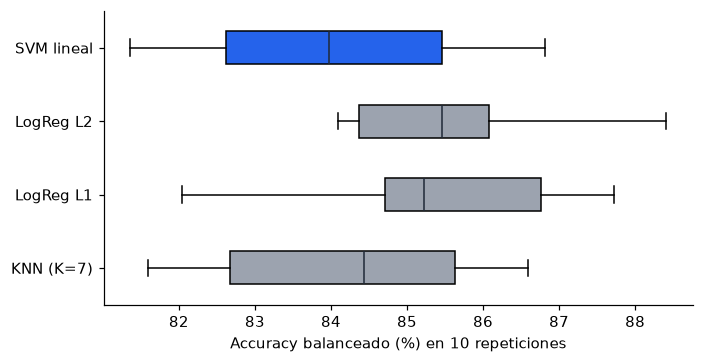

In [3]:
order = list(models)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
data = [res.loc[res.model == m, "bal_acc"] * 100 for m in order]
bp = ax.boxplot(data, vert=False, tick_labels=order, patch_artist=True, medianprops={'color': INK})
for patch, m in zip(bp['boxes'], order):
    patch.set_facecolor(ACCENT if m == BASELINE else MUTED)
ax.invert_yaxis()
ax.set_xlabel("Accuracy balanceado (%) en 10 repeticiones")
fig.tight_layout()
fig.savefig(FIG_DIR / "baselines_acc.png")
plt.show()

## Chequeos de confianza

**Etiquetas mezcladas.** Si se permutan las etiquetas, el accuracy balanceado debe caer a ~50 %. Si no, habría filtración de información en el protocolo.

In [4]:
Xb, yb = balanced_subsample(X, y, 0)
y_shuffled = pd.Series(np.random.default_rng(0).permutation(yb.values), index=yb.index)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
shuffled = {}
for name, model in models.items():
    pipe = Pipeline([*preprocessing_steps(), ("model", model)])
    shuffled[name] = error_rates(y_shuffled, cross_val_predict(pipe, Xb, y_shuffled, cv=cv))["bal_acc"]
(pd.Series(shuffled, name="acc. balanceado (%)") * 100).round(1).to_frame()

,acc. balanceado (%)
SVM lineal,48.6
LogReg L2,52.3
LogReg L1,51.4
KNN (K=7),47.7


**Preprocesamiento.** Se compara el recorte + estandarización con solo min-max (lo que hace el paper), promediando 3 repeticiones.

In [5]:
prepro = {"recorte + estandarizar": None, "solo min-max (como el paper)": [("scale", MinMaxScaler())]}
pieces = []
for pname, steps in prepro.items():
    r = repeated_balanced_cv(models, X, y, n_reps=3, n_splits=10, steps=steps)
    pieces.append(r.assign(prepro=pname))
cmp = pd.concat(pieces).pivot_table(index="model", columns="prepro", values="bal_acc") * 100
cmp.loc[order].round(1)

  -> Ejecutando repetición 1/3...


  -> Ejecutando repetición 2/3...


  -> Ejecutando repetición 3/3...


  -> Ejecutando repetición 1/3...


  -> Ejecutando repetición 2/3...


  -> Ejecutando repetición 3/3...


prepro,recorte + estandarizar,solo min-max (como el paper)
model,,
SVM lineal,83.9,85.8
LogReg L2,86.1,85.3
LogReg L1,85.6,85.9
KNN (K=7),84.8,80.5


## Conclusiones

Quedaron wenos los modelos iwal